# 2. Radar, GFS, AR test and figures (`precip` env)

MRMS hourly QPE (Pass2), GFS 0.25° analyses (IVT, PWAT, CAPE, 500 hPa), the object-based AR test, MRMS rain-object areas, OISST anomalies and the two figures. Run notebook 01 first: this notebook reads `event/pns_72h.csv`, `event/fl_asos_meta.csv`, `event/kmfl_pwat.csv` and the OISST files it writes.

Cells are the **original session code, verbatim, in the order they ran** (only local paths in outputs were shortened). Each cell starts with a comment giving the original session cell number, environment and status. Failed cells are kept and marked, because the next cell is usually the fix.

**Outputs are the recorded outputs of the original run** (printed text, and each figure embedded in the last cell that saved it), attached from the run log, not produced by re-executing the notebook. Very long printouts are truncated with a note.

In [ ]:
# Setup (added for the repo): run from the project folder; style.py is a stand-in for the figure style used in the session
import os, sys
if os.path.basename(os.getcwd())=='notebooks': os.chdir('..')
sys.path.insert(0, '.')
from style import apply_figure_style, panel_letter


In [ ]:
%%bash
# [orig cell 11 | env: precip | status: ok]
python -c "import cfgrib, xarray, cartopy, eccodes; print(cfgrib.__version__, xarray.__version__, cartopy.__version__)"; python -c "import gzip, matplotlib, scipy; print('ok')"

0.9.15.1 2026.9.0 0.26.0
ok


In [ ]:
%%bash
# [orig cell 12 | env: precip | status: ok]
mkdir -p event/gfs && cat > event/gfs_dl.py <<'EOF'
import requests, re, sys, os, pandas as pd
from concurrent.futures import ThreadPoolExecutor
B="https://noaa-gfs-bdp-pds.s3.amazonaws.com"
LEV=[1000,975,950,925,900,850,800,750,700,650,600,550,500,450,400,350,300]
want=[r':PWAT:entire atmosphere',r':HGT:500 mb:',r':PRMSL:mean sea level',r':CAPE:surface:',r':TMP:surface:',r':LAND:surface:',
      r':UGRD:250 mb:',r':VGRD:250 mb:',r':UGRD:10 m above',r':VGRD:10 m above',r':TMP:2 m above',r':DPT:2 m above',r':RH:2 m above']
for v in ['UGRD','VGRD','SPFH']:
    want += [rf':{v}:{l} mb:anl' for l in LEV]
want += [rf':HGT:{l} mb:anl' for l in (850,250)]
pat=re.compile('|'.join(want))
def get(t):
    d,h=t.strftime('%Y%m%d'),t.strftime('%H')
    out=f"event/gfs/gfs_{d}{h}.grib2"
    if os.path.exists(out) and os.path.getsize(out)>1e6: return out,'cached'
    u=f"{B}/gfs.{d}/{h}/atmos/gfs.t{h}z.pgrb2.0p25.f000"
    idx=requests.get(u+'.idx',timeout=60).text.strip().splitlines()
    rec=[l.split(':') for l in idx]; starts=[int(r[1]) for r in rec]
    chunks=[]
    for i,l in enumerate(idx):
        if pat.search(':'+':'.join(l.split(':')[3:])+':') or pat.search(l):
            end = starts[i+1]-1 if i+1<len(starts) else ''
            chunks.append((starts[i],end))
    with open(out,'wb') as f:
        for a,b in chunks:
            f.write(requests.get(u,headers={'Range':f'bytes={a}-{b}'},timeout=120).content)
    return out,len(chunks)
ts=pd.date_range('2026-10-31 00:00','2026-11-03 12:00',freq='6h')
with ThreadPoolExecutor(6) as ex:
    for r in ex.map(get,ts): print(r,flush=True)
EOF
echo ok

ok


In [ ]:
# [orig cell 13 | env: precip | status: ok]
import requests, gzip, os, io, re, numpy as np, pandas as pd, xarray as xr, tempfile
from concurrent.futures import ThreadPoolExecutor
os.makedirs('event/mrms',exist_ok=True)
B="https://noaa-mrms-pds.s3.amazonaws.com"
r=requests.get(f"{B}/?list-type=2&prefix=CONUS/MultiSensor_QPE_01H_Pass2_00.00/20261101/&max-keys=5",timeout=60).text
print(re.findall(r'<Key>(.*?)</Key>',r)[:3])


['CONUS/MultiSensor_QPE_01H_Pass2_00.00/20261101/MRMS_MultiSensor_QPE_01H_Pass2_00.00_20261101-000000.grib2.gz', 'CONUS/MultiSensor_QPE_01H_Pass2_00.00/20261101/MRMS_MultiSensor_QPE_01H_Pass2_00.00_20261101-010000.grib2.gz', 'CONUS/MultiSensor_QPE_01H_Pass2_00.00/20261101/MRMS_MultiSensor_QPE_01H_Pass2_00.00_20261101-020000.grib2.gz']


In [ ]:
# [orig cell 14 | env: precip | status: ok]
ts = pd.date_range('2026-10-31 13:00','2026-11-03 12:00',freq='h')  # hour-ending UTC
def dl(t):
    fn=f"event/mrms/q1h_{t:%Y%m%d%H}.grib2"
    if not os.path.exists(fn):
        u=f"{B}/CONUS/MultiSensor_QPE_01H_Pass2_00.00/{t:%Y%m%d}/MRMS_MultiSensor_QPE_01H_Pass2_00.00_{t:%Y%m%d-%H}0000.grib2.gz"
        rr=requests.get(u,timeout=120)
        if rr.status_code!=200: return None
        open(fn,'wb').write(gzip.decompress(rr.content))
    return fn
with ThreadPoolExecutor(8) as ex: files=list(ex.map(dl,ts))
print(sum(f is not None for f in files),'of',len(ts))
arrs=[]
for t,f in zip(ts,files):
    if f is None: arrs.append(None); continue
    ds=xr.open_dataset(f,engine='cfgrib',backend_kwargs={'indexpath':''})
    v=list(ds.data_vars)[0]
    sub=ds[v].sel(latitude=slice(29.6,24.4),longitude=slice(360-82.6,360-79.4)).load()
    arrs.append(sub.values.astype('float32')); lat=sub.latitude.values; lon=sub.longitude.values-360
    ds.close()
Q=np.stack([a if a is not None else np.full_like(arrs[0],np.nan) for a in arrs]); Q[Q<0]=np.nan
np.savez_compressed('event/mrms_q1h_fl.npz',Q=Q,lat=lat,lon=lon,time=ts.values.astype('datetime64[s]').astype('int64'))
print(Q.shape, np.nanmax(Q), lat[[0,-1]], lon[[0,-1]])


72 of 72
(72, 520, 320) 133.1 [29.595 24.405] [-82.59500135 -79.40500145]


In [ ]:
# [orig cell 15 | env: precip | status: ok]
LON,LAT=np.meshgrid(lon,lat)
tot=np.nansum(Q,0)
c=np.nancumsum(np.nan_to_num(Q),0); c=np.concatenate([np.zeros((1,)+c.shape[1:]),c])
r6=c[6:]-c[:-6]; r3=c[3:]-c[:-3]; r12=c[12:]-c[:-12]; r24=c[24:]-c[:-24]
boxes={'N Palm Beach':(26.65,26.95,-80.30,-80.03),'W Broward':(25.95,26.35,-80.45,-80.10),'S Brevard':(27.80,28.20,-80.80,-80.45)}
out=[]
for k,(a,b,c0,d) in boxes.items():
    m=(LAT>=a)&(LAT<=b)&(LON>=c0)&(LON<=d)
    def mx(F,lab,win):
        G=np.where(m[None],F,-1); i=np.unravel_index(np.argmax(G),G.shape)
        return {f'{lab}_mm':G[i], f'{lab}_end_utc':ts[i[0]+win-1], f'{lab}_lat':LAT[i[1:]], f'{lab}_lon':LON[i[1:]]}
    row={'core':k, 'max72h_mm':np.where(m,tot,-1).max()}
    for F,lab,w in [(Q,'1h',1),(r3,'3h',3),(r6,'6h',6),(r12,'12h',12),(r24,'24h',24)]: row.update(mx(F,lab,w))
    out.append(row)
M=pd.DataFrame(out); pd.set_option('display.width',250)
print(M[['core','max72h_mm','1h_mm','1h_end_utc','3h_mm','6h_mm','6h_end_utc','6h_lat','6h_lon','12h_mm','24h_mm','24h_end_utc']].round(2).to_string(index=False))
# compare to NWS 72h reports (obs end ~12Z Nov 3 = matches MRMS window)
R=pd.read_csv('event/pns_72h.csv') if os.path.exists('event/pns_72h.csv') else None
print(R is None)


        core  max72h_mm      1h_mm          1h_end_utc  3h_mm  6h_mm          6h_end_utc  6h_lat  6h_lon  12h_mm  24h_mm         24h_end_utc
N Palm Beach 515.900024 130.899994 2026-11-02 00:00:00  246.6  327.0 2026-11-02 02:00:00   26.78  -80.11   336.9   414.0 2026-11-02 19:00:00
   W Broward 260.600006  78.800003 2026-11-03 03:00:00  154.4  201.4 2026-11-03 03:00:00   26.17  -80.32   207.0   213.6 2026-11-03 05:00:00
   S Brevard 670.400024 133.100006 2026-11-02 14:00:00  286.6  431.9 2026-11-02 17:00:00   27.96  -80.54   552.4   627.2 2026-11-02 20:00:00
True


<kernel:4>:17: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  print(M[['core','max72h_mm','1h_mm','1h_end_utc','3h_mm','6h_mm','6h_end_utc','6h_lat','6h_lon','12h_mm','24h_mm','24h_end_utc']].round(2).to_string(index=False))

In [ ]:
%%bash
# [orig cell 16 | env: precip | status: ok]
# (ran in the background in the original session while cells 13-15 and notebook 01 cells ran)
python event/gfs_dl.py 2>&1 | tail -20

('event/gfs/gfs_2026103100.grib2', 66)
('event/gfs/gfs_2026103106.grib2', 66)
('event/gfs/gfs_2026103112.grib2', 66)
('event/gfs/gfs_2026103118.grib2', 66)
('event/gfs/gfs_2026110100.grib2', 66)
('event/gfs/gfs_2026110106.grib2', 66)
('event/gfs/gfs_2026110112.grib2', 66)
('event/gfs/gfs_2026110118.grib2', 66)
('event/gfs/gfs_2026110200.grib2', 66)
('event/gfs/gfs_2026110206.grib2', 66)
('event/gfs/gfs_2026110212.grib2', 66)
('event/gfs/gfs_2026110218.grib2', 66)
('event/gfs/gfs_2026110300.grib2', 66)
('event/gfs/gfs_2026110306.grib2', 66)
('event/gfs/gfs_2026110312.grib2', 66)


In [ ]:
# [orig cell 22 | env: precip | status: ok]
for d in ['20261030','20261031','20261101']:
    o=xr.open_dataset(f'event/oisst_{d}.nc').squeeze()
    box=lambda la0,la1,lo0,lo1: o.sel(lat=slice(la0,la1),lon=slice(360+lo0,360+lo1))
    a=box(25.5,28.5,-80.0,-78.5); b=box(24,32,-80,-70); c=box(22,26,-84,-80)
    print(d, 'GulfStream E of SE FL: SST %.2f anom %+.2f | W Atl 24-32N,80-70W anom %+.2f (max %+.2f) | Straits/SE Gulf anom %+.2f' % (
        float(a.sst.mean()),float(a.anom.mean()),float(b.anom.mean()),float(b.anom.max()),float(c.anom.mean())))


20261030 GulfStream E of SE FL: SST 28.01 anom +0.79 | W Atl 24-32N,80-70W anom +1.37 (max +2.44) | Straits/SE Gulf anom +0.25
20261031 GulfStream E of SE FL: SST 28.11 anom +0.93 | W Atl 24-32N,80-70W anom +1.44 (max +2.60) | Straits/SE Gulf anom +0.44
20261101 GulfStream E of SE FL: SST 28.12 anom +0.99 | W Atl 24-32N,80-70W anom +1.43 (max +2.61) | Straits/SE Gulf anom +0.59


In [ ]:
# [orig cell 23 | env: precip | status: error (failed in the original run; kept for the record)]
import glob, warnings; warnings.filterwarnings('ignore')
gts=pd.date_range('2026-10-31 00:00','2026-11-03 12:00',freq='6h')
SL=dict(latitude=slice(45,10),longitude=slice(255,305))
G={}
for t in gts:
    f=f"event/gfs/gfs_{t:%Y%m%d%H}.grib2"
    pl=xr.open_dataset(f,engine='cfgrib',backend_kwargs={'indexpath':'','filter_by_keys':{'typeOfLevel':'isobaricInhPa'}}).sel(**SL)
    ea=xr.open_dataset(f,engine='cfgrib',backend_kwargs={'indexpath':'','filter_by_keys':{'typeOfLevel':'atmosphere'}}).sel(**SL)
    sf=xr.open_dataset(f,engine='cfgrib',backend_kwargs={'indexpath':'','filter_by_keys':{'typeOfLevel':'surface','stepType':'instant'}}).sel(**SL)
    ms=xr.open_dataset(f,engine='cfgrib',backend_kwargs={'indexpath':'','filter_by_keys':{'typeOfLevel':'meanSea'}}).sel(**SL)
    lv=pl.isobaricInhPa
    q3=pl.q.sel(isobaricInhPa=lv[lv>=300]); u3=pl.u.sel(isobaricInhPa=lv[lv>=300]); v3=pl.v.sel(isobaricInhPa=lv[lv>=300])
    p=q3.isobaricInhPa*100
    qu=(q3*u3).integrate('isobaricInhPa')*100/9.81; qv=(q3*v3).integrate('isobaricInhPa')*100/9.81
    # integrate over descending coord gives negative -> take sign care
    sgn = -1 if q3.isobaricInhPa[0]>q3.isobaricInhPa[-1] else 1
    qu,qv = sgn*qu, sgn*qv
    G[t]=xr.Dataset(dict(ivtu=qu,ivtv=qv,ivt=np.hypot(qu,qv),pwat=ea.pwat,cape=sf.cape,sst=sf.t.where(sf.lsm<0.5) if 'lsm' in sf else sf.t,
                         z500=pl.gh.sel(isobaricInhPa=500),u250=pl.u.sel(isobaricInhPa=250),v250=pl.v.sel(isobaricInhPa=250),
                         u850=pl.u.sel(isobaricInhPa=850),v850=pl.v.sel(isobaricInhPa=850),q850=pl.q.sel(isobaricInhPa=850),mslp=ms.prmsl/100)).drop_vars([c for c in ['isobaricInhPa','step','surface','atmosphere','meanSea','valid_time'] if c in pl.coords or True],errors='ignore')
D=xr.concat([G[t] for t in gts],dim=pd.Index(gts,name='time'))
D.to_netcdf('event/gfs_diag.nc')
pts={'N Palm Beach':(26.78,-80.13),'W Broward':(26.15,-80.27),'S Brevard':(27.96,-80.56),'Miami':(25.75,-80.38)}
rows=[]
for k,(la,lo) in pts.items():
    s=D.sel(latitude=la,longitude=360+lo,method='nearest')
    rows.append(pd.DataFrame({'pt':k,'ivt':s.ivt.values,'ivt_dir':(np.degrees(np.arctan2(-s.ivtu,-s.ivtv))%360).values,'pwat':s.pwat.values,'cape':s.cape.values},index=gts))
Pt=pd.concat(rows); print(Pt[Pt.pt.isin(['N Palm Beach','S Brevard'])].round(0).to_string())
print('Domain max IVT per time:', D.ivt.max(['latitude','longitude']).round(0).values)


skipping variable: paramId==131 shortName='u'
Traceback (most recent call last):
  File "~/miniconda3/envs/precip/lib/python3.11/site-packages/cfgrib/dataset.py", line 726, in build_dataset_components
    dict_merge(variables, coord_vars)
  File "~/miniconda3/envs/precip/lib/python3.11/site-packages/cfgrib/dataset.py", line 642, in dict_merge
    raise DatasetBuildError(
cfgrib.dataset.DatasetBuildError: key present and new value is different: key='isobaricInhPa' value=Variable(dimensions=('isobaricInhPa',), data=array([850., 500., 250.])) new_value=Variable(dimensions=('isobaricInhPa',), data=array([1000.,  975.,  950.,  925.,  900.,  850.,  800.,  750.,  700.,
        650.,  600.,  550.,  500.,  450.,  400.,  350.,  300.,  250.]))
skipping variable: paramId==132 shortName='v'
Traceback (most recent call last):
  File "~/miniconda3/envs/precip/lib/python3.11/site-packages/cfgrib/dataset.py", line 726, in build_dataset_components
    dict_merge(variables, coord_vars)
  File "~/minicond

In [ ]:
# [orig cell 24 | env: precip | status: ok]
import cfgrib
dss=cfgrib.open_datasets('event/gfs/gfs_2026110200.grib2',backend_kwargs={'indexpath':''})
for d in dss: print(list(d.data_vars), {k:d[k].size for k in d.coords if d[k].ndim<=1 and k not in ('latitude','longitude')})


['pwat'] {'time': 1, 'step': 1, 'atmosphereSingleLayer': 1, 'valid_time': 1}
['u10', 'v10'] {'time': 1, 'step': 1, 'heightAboveGround': 1, 'valid_time': 1}
['t2m', 'd2m', 'r2'] {'time': 1, 'step': 1, 'heightAboveGround': 1, 'valid_time': 1}
['u', 'v'] {'time': 1, 'step': 1, 'isobaricInhPa': 18, 'valid_time': 1}
['q'] {'time': 1, 'step': 1, 'isobaricInhPa': 17, 'valid_time': 1}
['gh'] {'time': 1, 'step': 1, 'isobaricInhPa': 3, 'valid_time': 1}
['prmsl'] {'time': 1, 'step': 1, 'meanSea': 1, 'valid_time': 1}
['cape', 't', 'lsm'] {'time': 1, 'step': 1, 'surface': 1, 'valid_time': 1}


In [ ]:
# [orig cell 25 | env: precip | status: ok]
def load(t):
    dss=cfgrib.open_datasets(f"event/gfs/gfs_{t:%Y%m%d%H}.grib2",backend_kwargs={'indexpath':''})
    byv={v:d for d in dss for v in d.data_vars}
    s=lambda v: byv[v][v].sel(**SL).load()
    q=s('q'); u=s('u').sel(isobaricInhPa=q.isobaricInhPa); v=s('v').sel(isobaricInhPa=q.isobaricInhPa)
    p=q.isobaricInhPa.values*100.  # descending 1000..300
    qu=np.trapezoid((q*u).values,p,axis=0)*-1/9.81; qv=np.trapezoid((q*v).values,p,axis=0)*-1/9.81
    lat=q.latitude.values; lon=q.longitude.values-360
    gh=s('gh'); uu=s('u'); vv=s('v'); sf=byv['cape']
    return dict(ivtu=qu,ivtv=qv,ivt=np.hypot(qu,qv),pwat=s('pwat').values,cape=s('cape').values,
                sst=np.where(sf['lsm'].sel(**SL).values<0.5,sf['t'].sel(**SL).values-273.15,np.nan),
                z500=gh.sel(isobaricInhPa=500).values/10,u250=uu.sel(isobaricInhPa=250).values,v250=vv.sel(isobaricInhPa=250).values,
                u850=uu.sel(isobaricInhPa=850).values,v850=vv.sel(isobaricInhPa=850).values,mslp=s('prmsl').values/100,
                u10=s('u10').values,v10=s('v10').values), lat, lon
recs=[load(t) for t in gts]; glat,glon=recs[0][1],recs[0][2]
D=xr.Dataset({k:(('time','lat','lon'),np.stack([r[0][k] for r in recs])) for k in recs[0][0]},coords=dict(time=gts,lat=glat,lon=glon))
D.to_netcdf('event/gfs_diag.nc')
pts={'N Palm Beach':(26.78,-80.13),'W Broward':(26.15,-80.27),'S Brevard':(27.96,-80.56)}
rows=[]
for k,(la,lo) in pts.items():
    s=D.sel(lat=la,lon=lo,method='nearest')
    rows.append(pd.DataFrame({'pt':k,'ivt':s.ivt.values,'ivt_dir_from':(np.degrees(np.arctan2(-s.ivtu,-s.ivtv))%360).values,'pwat':s.pwat.values,'cape':s.cape.values},index=gts))
Pt=pd.concat(rows); print(Pt.round(0).to_string())
fl=D.sel(lat=slice(30,24),lon=slice(-84,-78))
print('max IVT over FL box by time:', fl.ivt.max(['lat','lon']).round(0).values)
print('max PWAT over FL box:', fl.pwat.max(['lat','lon']).round(1).values)


                               pt    ivt  ivt_dir_from  pwat    cape
2026-10-31 00:00:00  N Palm Beach  327.0          80.0  46.0   879.0
2026-10-31 06:00:00  N Palm Beach  366.0          90.0  49.0   682.0
2026-10-31 12:00:00  N Palm Beach  303.0          91.0  43.0   597.0
2026-10-31 18:00:00  N Palm Beach  308.0          93.0  46.0  1227.0
2026-11-01 00:00:00  N Palm Beach  359.0          90.0  46.0  1082.0
2026-11-01 06:00:00  N Palm Beach  365.0         101.0  46.0   991.0
2026-11-01 12:00:00  N Palm Beach  385.0          97.0  51.0  1065.0
2026-11-01 18:00:00  N Palm Beach  368.0         118.0  55.0  1030.0
2026-11-02 00:00:00  N Palm Beach  283.0         136.0  52.0  1035.0
2026-11-02 06:00:00  N Palm Beach  418.0         128.0  52.0   828.0
2026-11-02 12:00:00  N Palm Beach  345.0         148.0  53.0   602.0
2026-11-02 18:00:00  N Palm Beach  348.0         132.0  53.0   986.0
2026-11-03 00:00:00  N Palm Beach  393.0         124.0  55.0   471.0
2026-11-03 06:00:00  N Palm Beach 

In [ ]:
# [orig cell 26 | env: precip | status: ok]
from scipy import ndimage
R_E=6371.
Lg,Ag=np.meshgrid(D.lon.values,D.lat.values)
cell_area=(R_E*np.radians(.25))**2*np.cos(np.radians(Ag))
def gc(la1,lo1,la2,lo2):
    p=np.pi/180; a=np.sin((la2-la1)*p/2)**2+np.cos(la1*p)*np.cos(la2*p)*np.sin((lo2-lo1)*p/2)**2; return 2*R_E*np.arcsin(np.sqrt(a))
rows=[]
for i,t in enumerate(gts):
    ivt=D.ivt.values[i]; lab,n=ndimage.label(ivt>=250)
    for k,(la,lo) in pts.items():
        j=np.argmin(abs(D.lat.values-la)); jj=np.argmin(abs(D.lon.values-lo)); L=lab[j,jj]
        if L==0: rows.append(dict(time=t,pt=k,in_obj=False)); continue
        m=lab==L; area=cell_area[m].sum()
        la_,lo_=Ag[m],Lg[m]
        # length: max great-circle distance between object points (subsample)
        idx=np.random.default_rng(0).choice(m.sum(),min(1500,m.sum()),replace=False)
        A=la_[idx];B=lo_[idx]; dd=gc(A[:,None],B[:,None],A[None],B[None]); length=dd.max()
        w=ivt[m]; u=(D.ivtu.values[i][m]*w).sum()/w.sum(); v=(D.ivtv.values[i][m]*w).sum()/w.sum()
        a,b=np.unravel_index(dd.argmax(),dd.shape); orient=np.degrees(np.arctan2(B[b]-B[a],A[b]-A[a]))%180
        flowdir=np.degrees(np.arctan2(u,v))%180
        rows.append(dict(time=t,pt=k,in_obj=True,area_1e6km2=area/1e6,length_km=length,LW=length**2/area,
                         mean_ivtu=u,mean_ivtv_poleward=v,touches_E_edge=bool(m[:,-1].any()),lat_span=(la_.min(),la_.max()),lon_span=(lo_.min(),lo_.max()),
                         orient_vs_flow_deg=min(abs(orient-flowdir),180-abs(orient-flowdir))))
AR=pd.DataFrame(rows)
print(AR[AR.pt=='N Palm Beach'].drop(columns='pt').round(1).to_string(index=False))


               time  in_obj  area_1e6km2  length_km  LW  mean_ivtu  mean_ivtv_poleward touches_E_edge       lat_span         lon_span  orient_vs_flow_deg
2026-10-31 00:00:00    True          0.3     1196.7 5.2     -291.4               -61.1          False  (25.75, 30.5)  (-87.5, -75.75)                25.0
2026-10-31 06:00:00    True          0.3     1024.2 3.5     -293.6                41.4          False   (25.5, 30.5)  (-86.5, -76.75)                16.7
2026-10-31 12:00:00    True          0.5     1897.9 6.7     -273.2                 3.7          False  (25.25, 31.5)   (-87.5, -68.5)                11.1
2026-10-31 18:00:00    True          0.5     1835.4 7.3     -271.3                19.4          False  (25.0, 30.25)  (-88.0, -69.75)                 7.5
2026-11-01 00:00:00    True          1.0     2807.5 7.6     -212.5                69.5          False (24.25, 37.25)  (-95.25, -67.5)                 0.9
2026-11-01 06:00:00    True          1.4     2782.8 5.6     -177.8          

In [ ]:
# [orig cell 27 | env: precip | status: ok]
cellA=(111.19*0.01)**2*np.cos(np.radians(LAT))
def obj(t,la,lo,thr):
    i=list(ts).index(pd.Timestamp(t)); F=np.nan_to_num(Q[i]); lab,n=ndimage.label(F>=thr)
    j=np.argmin(abs(lat-la)); jj=np.argmin(abs(lon-lo))
    # take largest object within 10 km of point
    win=lab[j-10:j+11,jj-10:jj+11]; ids=[x for x in np.unique(win) if x>0]
    if not ids: return 0,False
    best=max(ids,key=lambda x:(lab==x).sum()); m=lab==best
    return cellA[m].sum(), bool(m[:,-1].any() or m[:,0].any() or m[0].any() or m[-1].any())
peaks={'N Palm Beach':('2026-11-02 00:00',26.78,-80.11),'S Brevard':('2026-11-02 14:00',27.96,-80.54),'W Broward':('2026-11-03 03:00',26.17,-80.32)}
for k,(t,la,lo) in peaks.items():
    for thr in (2,10):
        a,edge=obj(t,la,lo,thr); print(f"{k:13s} peak hour ending {t}Z  ≥{thr} mm/h object area = {a:,.0f} km²  (touches domain edge: {edge})")
# hours with ≥ 50 mm/h anywhere per core; duration of heavy rain at the max-72h pixel
for k,(a,b,c0,d) in boxes.items():
    m=(LAT>=a)&(LAT<=b)&(LON>=c0)&(LON<=d); i=np.unravel_index(np.argmax(np.where(m,tot,-1)),tot.shape)
    s=Q[:,i[0],i[1]]; print(k,'max-total pixel',LAT[i].round(3),LON[i].round(3),'total',tot[i].round(0),'mm; hours ≥25 mm/h:',int((s>=25).sum()),'; hours ≥10:',int((s>=10).sum()))


N Palm Beach  peak hour ending 2026-11-02 00:00Z  ≥2 mm/h object area = 36,333 km²  (touches domain edge: True)
N Palm Beach  peak hour ending 2026-11-02 00:00Z  ≥10 mm/h object area = 437 km²  (touches domain edge: False)
S Brevard     peak hour ending 2026-11-02 14:00Z  ≥2 mm/h object area = 45,482 km²  (touches domain edge: True)
S Brevard     peak hour ending 2026-11-02 14:00Z  ≥10 mm/h object area = 8,485 km²  (touches domain edge: False)
W Broward     peak hour ending 2026-11-03 03:00Z  ≥2 mm/h object area = 4,123 km²  (touches domain edge: False)
W Broward     peak hour ending 2026-11-03 03:00Z  ≥10 mm/h object area = 1,675 km²  (touches domain edge: False)
N Palm Beach max-total pixel 26.775 -80.105 total 516.0 mm; hours ≥25 mm/h: 7 ; hours ≥10: 9
W Broward max-total pixel 26.155 -80.315 total 261.0 mm; hours ≥25 mm/h: 2 ; hours ≥10: 7
S Brevard max-total pixel 27.945 -80.535 total 670.0 mm; hours ≥25 mm/h: 8 ; hours ≥10: 12


In [ ]:
# [orig cell 29 | env: precip | status: ok]
try:
    apply_figure_style; print('available')
except NameError: print('missing')


available


In [ ]:
# [orig cell 30 | env: precip | status: error (failed in the original run; kept for the record)]
import matplotlib as mpl, matplotlib.pyplot as plt, cartopy.crs as ccrs, cartopy.feature as cf
from matplotlib.colors import BoundaryNorm
apply_figure_style(sizes=(8,7,6))
R=pd.read_csv('event/pns_72h.csv')
# MRMS vs gauge at report locations (nearest pixel and 3x3 max)
def mr(la,lo,k=1):
    j=np.argmin(abs(lat-la)); jj=np.argmin(abs(lon-lo)); return tot[max(j-k,0):j+k+1,max(jj-k,0):jj+k+1].max(), tot[j,jj]
R[['mrms3x3_mm','mrms_px_mm']]=[mr(a,b) for a,b in zip(R.lat,R.lon)]
R['gauge_mm']=R.inch*25.4
inb=R[(R.lat<29.5)&(R.lat>24.5)&(R.lon>-82.5)&(R.lon<-79.5)&(R.gauge_mm>=100)]
print('n gauges ≥100 mm:',len(inb),' median MRMS/gauge (pixel):',(inb.mrms_px_mm/inb.gauge_mm).median().round(2),
      ' r=',np.corrcoef(inb.mrms_px_mm,inb.gauge_mm)[0,1].round(2))
top=R[R.gauge_mm>=380]; print(top[['county','loc','inch','gauge_mm','mrms_px_mm']].round(0).to_string(index=False))
R.to_csv('event/pns_72h_vs_mrms.csv',index=False)

lev=[0,25,50,75,100,150,200,250,300,400,500,600,700]
cmap=plt.get_cmap('YlGnBu',len(lev)-1); norm=BoundaryNorm(lev,cmap.N)
fig=plt.figure(figsize=(7.2,6.4))
ax=fig.add_axes([0.06,0.06,0.48,0.88],projection=ccrs.PlateCarree())
ext=[-81.35,-79.85,25.55,28.45]; ax.set_extent(ext)
m=ax.pcolormesh(lon,lat,np.where(tot>=5,tot,np.nan),cmap=cmap,norm=norm,shading='auto',rasterized=True)
ax.add_feature(cf.COASTLINE.with_scale('10m'),lw=.5); ax.add_feature(cf.STATES.with_scale('10m'),lw=.3,ec='0.5')
g=R[(R.lon>ext[0])&(R.lat>ext[2])&(R.lat<ext[3])]
ax.scatter(g.lon,g.lat,c=g.gauge_mm,cmap=cmap,norm=norm,s=12,ec='k',lw=.35,zorder=3)
asos=pd.read_csv('event/fl_asos_meta.csv') if os.path.exists('event/fl_asos_meta.csv') else None
for sid in ['DJT','F45','FXE','FLL','PMP','MLB','X26','VRB','FPR','MIA']:
    r_=asos[asos.sid==sid].iloc[0]; ax.plot(r_.lon,r_.lat,marker='^',ms=4,mfc='w',mec='k',mew=.6,zorder=4)
    ax.text(r_.lon+0.03,r_.lat,sid,fontsize=6,va='center',zorder=4)
for k,(la,lo,txt_) in {'a':(26.775,-80.105,'N Palm Beach\n516 mm (MRMS)\n589 mm gauge'),'b':(27.945,-80.535,'S Brevard\n670 mm (MRMS)\n627 mm gauge'),'c':(26.155,-80.315,'W Broward\n261 mm (MRMS)\n286 mm gauge')}.items():
    ax.annotate(txt_,(lo,la),xytext=(lo-0.62 if k!='b' else lo-0.7,la+(0.12 if k!='c' else -0.2)),fontsize=7,arrowprops=dict(arrowstyle='-',lw=.6),ha='left')
cb=fig.colorbar(m,ax=ax,orientation='horizontal',fraction=0.04,pad=0.03,ticks=lev[::2]); cb.set_label('72-h rainfall, 31 Oct 13 UTC – 3 Nov 12 UTC (mm)')
ax.set_title('Three rainfall cores along the Atlantic coast',loc='left')
panel_letter(ax,'a')
# hyetographs
cores3=[('N Palm Beach',26.775,-80.105,'#1b6ca8'),('S Brevard',27.945,-80.535,'#7a3e9d'),('W Broward',26.155,-80.315,'#d9822b')]
axs=[fig.add_axes([0.63,0.70-i*0.30,0.34,0.22]) for i in range(3)]
tl=ts-pd.Timedelta(hours=5)  # EST (after 1 Nov 06 UTC); label as local EST
for a_,(nm_,la,lo,colr) in zip(axs,cores3):
    j=np.argmin(abs(lat-la)); jj=np.argmin(abs(lon-lo)); s=Q[:,j,jj]
    a_.bar(tl,s,width=1/24,color=colr,align='edge')
    a2=a_.twinx(); a2.plot(tl+pd.Timedelta(hours=1),np.nancumsum(s),color='0.25',lw=1); a2.set_ylim(0,720)
    a_.set_ylim(0,140); a_.set_ylabel('mm/h'); a2.set_ylabel('cumulative (mm)',color='0.25')
    a_.set_title(f'{nm_}: peak {np.nanmax(s):.0f} mm/h, total {np.nansum(s):.0f} mm',loc='left',fontsize=7)
    a_.xaxis.set_major_formatter(mpl.dates.DateFormatter('%d %b\n%H:%M')); a_.set_xlim(tl[0],tl[-1]+pd.Timedelta(hours=1))
    if a_ is not axs[-1]: a_.set_xticklabels([])
axs[-1].set_xlabel('Local time (EST)'); panel_letter(axs[0],'b')
fig.savefig('fig1_rainfall_cores.png',dpi=300)
print('ok')


n gauges ≥100 mm: 334  median MRMS/gauge (pixel): 1.01  r= 0.87
    county                          loc  inch  gauge_mm  mrms_px_mm
Palm Beach            3 W Riviera Beach  23.0     589.0       476.0
Palm Beach             2 NE The Acreage  19.0     489.0       217.0
Palm Beach            2 W Riviera Beach  16.0     402.0       499.0
       NaN          2 NE Grant-Valkaria  23.0     578.0       636.0
       NaN          1 S Melbourne Beach  21.0     530.0       449.0
   Brevard           1 N Grant-Valkaria  25.0     627.0       645.0
   Brevard                  2 E Malabar  25.0     623.0       644.0
   Brevard                 1 S Palm Bay  22.0     559.0       420.0
   Brevard            2 E Bayside Lakes  20.0     516.0       432.0
   Brevard            1 E Bayside Lakes  20.0     516.0       432.0
   Brevard                 3 W Palm Bay  20.0     500.0       412.0
   Brevard                2 NE Palm Bay  19.0     494.0       443.0
   Brevard                 3 NW Malabar  19.0     49

Matplotlib is building the font cache; this may take a moment.
Traceback (most recent call last):
  File "<kernel:13>", line 28, in <module>
    r_=asos[asos.sid==sid].iloc[0]; ax.plot(r_.lon,r_.lat,marker='^',ms=4,mfc='w',mec='k',mew=.6,zorder=4)
            ^^^^^^^^
AttributeError: 'NoneType' object has no attribute 'sid'


In [ ]:
# [orig cell 32 | env: precip | status: error (failed in the original run; kept for the record)]
asos=pd.read_csv('event/fl_asos_meta.csv')
fig=plt.figure(figsize=(7.2,6.4))
ax=fig.add_axes([0.05,0.10,0.50,0.84],projection=ccrs.PlateCarree())
ext=[-81.35,-79.85,25.55,28.45]; ax.set_extent(ext)
m=ax.pcolormesh(lon,lat,np.where(tot>=5,tot,np.nan),cmap=cmap,norm=norm,shading='auto',rasterized=True)
ax.add_feature(cf.COASTLINE.with_scale('10m'),lw=.5); ax.add_feature(cf.LAKES.with_scale('10m'),fc='none',ec='0.4',lw=.4)
g=R[(R.lon>ext[0])&(R.lat>ext[2])&(R.lat<ext[3])]
ax.scatter(g.lon,g.lat,c=g.gauge_mm,cmap=cmap,norm=norm,s=11,ec='k',lw=.35,zorder=3,label='NWS gauge report (72 h)')
for sid in ['DJT','F45','FXE','FLL','PMP','MLB','X26','VRB','FPR','MIA']:
    r_=asos[asos.sid==sid].iloc[0]; ax.plot(r_.lon,r_.lat,marker='^',ms=4.5,mfc='w',mec='k',mew=.7,zorder=4,ls='none')
    ax.text(r_.lon+0.035,r_.lat-0.01,sid,fontsize=6,va='center',zorder=4)
ax.plot([],[],marker='^',ms=4.5,mfc='w',mec='k',ls='none',label='ASOS station')
ax.legend(loc='lower left',frameon=False,fontsize=7)
for la,lo,txt_,dx,dy in [(26.775,-80.105,'N Palm Beach\nMRMS 516 mm\ngauge 589 mm',-0.95,0.28),(27.945,-80.535,'S Brevard\nMRMS 670 mm\ngauge 627 mm',-0.78,0.22),(26.155,-80.315,'W Broward\nMRMS 261 mm\ngauge 286 mm',-0.95,-0.12)]:
    ax.annotate(txt_,(lo,la),xytext=(lo+dx,la+dy),fontsize=7,arrowprops=dict(arrowstyle='-',lw=.6),ha='left',va='center')
cb=fig.colorbar(m,ax=ax,orientation='horizontal',fraction=0.035,pad=0.02,ticks=lev[::2]); cb.set_label('72-h rainfall, 31 Oct 13 UTC – 3 Nov 12 UTC (mm)')
ax.set_title('Three rainfall cores along the Atlantic coast',loc='left')
panel_letter(ax,'a')
axs=[fig.add_axes([0.64,0.71-i*0.29,0.27,0.20]) for i in range(3)]
tl=(ts-pd.Timedelta(hours=1)-pd.Timedelta(hours=5))  # hour start, EST
for a_,(nm_,la,lo,colr) in zip(axs,cores3):
    j=np.argmin(abs(lat-la)); jj=np.argmin(abs(lon-lo)); s=Q[:,j,jj]
    a_.bar(tl,s,width=1/24,color=colr,align='edge')
    a2=a_.twinx(); a2.plot(tl+pd.Timedelta(hours=1),np.nancumsum(s),color='0.25',lw=1); a2.set_ylim(0,720)
    a_.set_ylim(0,140); a_.set_ylabel('mm per hour'); a2.set_ylabel('cumulative (mm)',color='0.25')
    a_.set_title(f'{nm_}: peak {np.nanmax(s):.0f} mm/h, total {np.nansum(s):.0f} mm',loc='left',fontsize=7)
    a_.xaxis.set_major_locator(mpl.dates.DayLocator()); a_.xaxis.set_major_formatter(mpl.dates.DateFormatter('%d %b'))
    a_.set_xlim(tl[0],tl[-1]+pd.Timedelta(hours=1))
    if a_ is not axs[-1]: a_.set_xticklabels([])
axs[-1].set_xlabel('Local time (EST), MRMS pixel of max 72-h total'); panel_letter(axs[0],'b')
fig.savefig('fig1_rainfall_cores.png',dpi=300)
r=fig.canvas.get_renderer()
texts=[(t,t.get_window_extent(r)) for t in fig.findobj(mpl.text.Text) if t.get_text().strip() and t.get_visible()]
ov=[(a.get_text()[:20],b.get_text()[:20]) for i,(a,ba) in enumerate(texts) for b,bb in texts[i+1:] if ba.overlaps(bb)]
print(ov[:10])


Traceback (most recent call last):
  File "<kernel:14>", line 22, in <module>
    for a_,(nm_,la,lo,colr) in zip(axs,cores3):
                                       ^^^^^^
NameError: name 'cores3' is not defined


In [ ]:
# [orig cell 33 | env: precip | status: error (failed in the original run; kept for the record)]
cores3=[('N Palm Beach',26.775,-80.105,'#1b6ca8'),('S Brevard',27.945,-80.535,'#7a3e9d'),('W Broward',26.155,-80.315,'#d9822b')]
plt.close('all')
exec(open('/dev/null').read())
fig=plt.figure(figsize=(7.2,6.4))
ax=fig.add_axes([0.05,0.10,0.50,0.84],projection=ccrs.PlateCarree())
ext=[-81.35,-79.85,25.55,28.45]; ax.set_extent(ext)
m=ax.pcolormesh(lon,lat,np.where(tot>=5,tot,np.nan),cmap=cmap,norm=norm,shading='auto',rasterized=True)
ax.add_feature(cf.COASTLINE.with_scale('10m'),lw=.5); ax.add_feature(cf.LAKES.with_scale('10m'),fc='none',ec='0.4',lw=.4)
g=R[(R.lon>ext[0])&(R.lat>ext[2])&(R.lat<ext[3])]
ax.scatter(g.lon,g.lat,c=g.gauge_mm,cmap=cmap,norm=norm,s=11,ec='k',lw=.35,zorder=3,label='NWS gauge report (72 h)')
for sid in ['DJT','F45','FXE','FLL','PMP','MLB','X26','VRB','FPR','MIA']:
    r_=asos[asos.sid==sid].iloc[0]; ax.plot(r_.lon,r_.lat,marker='^',ms=4.5,mfc='w',mec='k',mew=.7,zorder=4,ls='none')
    ax.text(r_.lon+0.035,r_.lat-0.01,sid,fontsize=6,va='center',zorder=4)
ax.plot([],[],marker='^',ms=4.5,mfc='w',mec='k',ls='none',label='ASOS station')
ax.legend(loc='lower left',frameon=False,fontsize=7)
for la,lo,txt_,dx,dy in [(26.775,-80.105,'N Palm Beach\nMRMS 516 mm\ngauge 589 mm',-0.95,0.28),(27.945,-80.535,'S Brevard\nMRMS 670 mm\ngauge 627 mm',-0.78,0.22),(26.155,-80.315,'W Broward\nMRMS 261 mm\ngauge 286 mm',-0.95,-0.12)]:
    ax.annotate(txt_,(lo,la),xytext=(lo+dx,la+dy),fontsize=7,arrowprops=dict(arrowstyle='-',lw=.6),ha='left',va='center')
cb=fig.colorbar(m,ax=ax,orientation='horizontal',fraction=0.035,pad=0.02,ticks=lev[::2]); cb.set_label('72-h rainfall, 31 Oct 13 UTC – 3 Nov 12 UTC (mm)')
ax.set_title('Three rainfall cores along the Atlantic coast',loc='left')
panel_letter(ax,'a')
axs=[fig.add_axes([0.64,0.71-i*0.29,0.27,0.20]) for i in range(3)]
tl=(ts-pd.Timedelta(hours=1)-pd.Timedelta(hours=5))
for a_,(nm_,la,lo,colr) in zip(axs,cores3):
    j=np.argmin(abs(lat-la)); jj=np.argmin(abs(lon-lo)); s=Q[:,j,jj]
    a_.bar(tl,s,width=1/24,color=colr,align='edge')
    a2=a_.twinx(); a2.plot(tl+pd.Timedelta(hours=1),np.nancumsum(s),color='0.25',lw=1); a2.set_ylim(0,720)
    a_.set_ylim(0,140); a_.set_ylabel('mm per hour'); a2.set_ylabel('cumulative (mm)',color='0.25')
    a_.set_title(f'{nm_}: peak {np.nanmax(s):.0f} mm/h, total {np.nansum(s):.0f} mm',loc='left',fontsize=7)
    a_.xaxis.set_major_locator(mpl.dates.DayLocator()); a_.xaxis.set_major_formatter(mpl.dates.DateFormatter('%d %b'))
    a_.set_xlim(tl[0],tl[-1]+pd.Timedelta(hours=1))
    if a_ is not axs[-1]: a_.set_xticklabels([])
axs[-1].set_xlabel('Local time (EST), MRMS pixel of max 72-h total'); panel_letter(axs[0],'b')
fig.savefig('fig1_rainfall_cores.png',dpi=300)
r=fig.canvas.get_renderer()
texts=[(t,t.get_window_extent(r)) for t in fig.findobj(mpl.text.Text) if t.get_text().strip() and t.get_visible()]
print([(a.get_text()[:20],b.get_text()[:20]) for i,(a,ba) in enumerate(texts) for b,bb in texts[i+1:] if ba.overlaps(bb)][:10])


Traceback (most recent call last):
  File "~/miniconda3/envs/precip/lib/python3.11/pathlib.py", line 1116, in mkdir
    os.mkdir(self, mode)
FileNotFoundError: [Errno 2] No such file or directory: '~/.local/share/cartopy/shapefiles/natural_earth/physical'

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "~/miniconda3/envs/precip/lib/python3.11/pathlib.py", line 1116, in mkdir
    os.mkdir(self, mode)
FileNotFoundError: [Errno 2] No such file or directory: '~/.local/share/cartopy/shapefiles/natural_earth'

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "~/miniconda3/envs/precip/lib/python3.11/pathlib.py", line 1116, in mkdir
    os.mkdir(self, mode)
FileNotFoundError: [Errno 2] No such file or directory: '~/.local/share/cartopy/shapefiles'

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "<kernel:15>

In [ ]:
# [orig cell 34 | env: precip | status: ok]
import cartopy
os.makedirs('cartopy_data',exist_ok=True); cartopy.config['data_dir']=os.path.abspath('cartopy_data')
try:
    from cartopy.io import shapereader
    p=shapereader.natural_earth('10m','physical','coastline'); print('ok',p)
except Exception as e: print('ERR',type(e).__name__,str(e)[:200])


ok ./cartopy_data/shapefiles/natural_earth/physical/ne_10m_coastline.shp


In [ ]:
# [orig cell 35 | env: precip | status: ok]
for nm in [('physical','lakes'),('cultural','admin_1_states_provinces_lakes')]: shapereader.natural_earth('10m',*nm)
plt.close('all')
fig=plt.figure(figsize=(7.2,6.4))
ax=fig.add_axes([0.05,0.10,0.50,0.84],projection=ccrs.PlateCarree())
ext=[-81.35,-79.85,25.55,28.45]; ax.set_extent(ext)
m=ax.pcolormesh(lon,lat,np.where(tot>=5,tot,np.nan),cmap=cmap,norm=norm,shading='auto',rasterized=True)
ax.add_feature(cf.COASTLINE.with_scale('10m'),lw=.5); ax.add_feature(cf.LAKES.with_scale('10m'),fc='none',ec='0.4',lw=.4)
g=R[(R.lon>ext[0])&(R.lat>ext[2])&(R.lat<ext[3])]
ax.scatter(g.lon,g.lat,c=g.gauge_mm,cmap=cmap,norm=norm,s=11,ec='k',lw=.35,zorder=3,label='NWS gauge report (72 h)')
for sid in ['DJT','F45','FXE','FLL','PMP','MLB','X26','VRB','FPR','MIA']:
    r_=asos[asos.sid==sid].iloc[0]; ax.plot(r_.lon,r_.lat,marker='^',ms=4.5,mfc='w',mec='k',mew=.7,zorder=4,ls='none')
    ax.text(r_.lon+0.035,r_.lat-0.01,sid,fontsize=6,va='center',zorder=4)
ax.plot([],[],marker='^',ms=4.5,mfc='w',mec='k',ls='none',label='ASOS station')
ax.legend(loc='lower left',frameon=False,fontsize=7)
for la,lo,txt_,dx,dy in [(26.775,-80.105,'N Palm Beach\nMRMS 516 mm\ngauge 589 mm',-0.95,0.28),(27.945,-80.535,'S Brevard\nMRMS 670 mm\ngauge 627 mm',-0.78,0.22),(26.155,-80.315,'W Broward\nMRMS 261 mm\ngauge 286 mm',-0.95,-0.12)]:
    ax.annotate(txt_,(lo,la),xytext=(lo+dx,la+dy),fontsize=7,arrowprops=dict(arrowstyle='-',lw=.6),ha='left',va='center')
cb=fig.colorbar(m,ax=ax,orientation='horizontal',fraction=0.035,pad=0.02,ticks=lev[::2]); cb.set_label('72-h rainfall, 31 Oct 13 UTC – 3 Nov 12 UTC (mm)')
ax.set_title('Three rainfall cores along the Atlantic coast',loc='left')
panel_letter(ax,'a')
axs=[fig.add_axes([0.64,0.71-i*0.29,0.27,0.20]) for i in range(3)]
tl=(ts-pd.Timedelta(hours=1)-pd.Timedelta(hours=5))
for a_,(nm_,la,lo,colr) in zip(axs,cores3):
    j=np.argmin(abs(lat-la)); jj=np.argmin(abs(lon-lo)); s=Q[:,j,jj]
    a_.bar(tl,s,width=1/24,color=colr,align='edge')
    a2=a_.twinx(); a2.plot(tl+pd.Timedelta(hours=1),np.nancumsum(s),color='0.25',lw=1); a2.set_ylim(0,720)
    a_.set_ylim(0,140); a_.set_ylabel('mm per hour'); a2.set_ylabel('cumulative (mm)',color='0.25')
    a_.set_title(f'{nm_}: peak {np.nanmax(s):.0f} mm/h, total {np.nansum(s):.0f} mm',loc='left',fontsize=7)
    a_.xaxis.set_major_locator(mpl.dates.DayLocator()); a_.xaxis.set_major_formatter(mpl.dates.DateFormatter('%d %b'))
    a_.set_xlim(tl[0],tl[-1]+pd.Timedelta(hours=1))
    if a_ is not axs[-1]: a_.set_xticklabels([])
axs[-1].set_xlabel('Local time (EST), MRMS pixel of max 72-h total'); panel_letter(axs[0],'b')
fig.savefig('fig1_rainfall_cores.png',dpi=300)
r=fig.canvas.get_renderer()
texts=[(t,t.get_window_extent(r)) for t in fig.findobj(mpl.text.Text) if t.get_text().strip() and t.get_visible()]
print([(a.get_text()[:20],b.get_text()[:20]) for i,(a,ba) in enumerate(texts) for b,bb in texts[i+1:] if ba.overlaps(bb)][:10])


[('F45', 'N Palm Beach\nMRMS 51'), ('FXE', 'PMP'), ('MLB', 'S Brevard\nMRMS 670 m'), ('N Palm Beach: peak 1', '800')]


In [ ]:
# [orig cell 37 | env: precip | status: ok]
plt.close('all')
fig=plt.figure(figsize=(7.2,6.4))
ax=fig.add_axes([0.07,0.13,0.44,0.81],projection=ccrs.PlateCarree())
ax.set_extent(ext)
m=ax.pcolormesh(lon,lat,np.where(tot>=5,tot,np.nan),cmap=cmap,norm=norm,shading='auto',rasterized=True)
ax.add_feature(cf.COASTLINE.with_scale('10m'),lw=.5); ax.add_feature(cf.LAKES.with_scale('10m'),fc='none',ec='0.4',lw=.4)
ax.scatter(g.lon,g.lat,c=g.gauge_mm,cmap=cmap,norm=norm,s=11,ec='k',lw=.35,zorder=3,label='NWS gauge report (72 h)')
left={'MLB','FXE','F45'}
for sid in ['DJT','F45','FXE','FLL','PMP','MLB','X26','VRB','FPR','MIA']:
    r_=asos[asos.sid==sid].iloc[0]; ax.plot(r_.lon,r_.lat,marker='^',ms=4.5,mfc='w',mec='k',mew=.7,zorder=4,ls='none')
    ax.text(r_.lon+(-0.035 if sid in left else 0.035),r_.lat-0.01,sid,fontsize=6,va='center',ha='right' if sid in left else 'left',zorder=4,
            bbox=dict(fc='w',ec='none',pad=0.3,alpha=.7))
ax.plot([],[],marker='^',ms=4.5,mfc='w',mec='k',ls='none',label='ASOS station')
ax.legend(loc='lower left',frameon=False,fontsize=7)
for la,lo,txt_,tx,ty in [(26.775,-80.105,'N Palm Beach\nMRMS 516 mm\ngauge 589 mm',-81.30,26.40),(27.945,-80.535,'S Brevard\nMRMS 670 mm\ngauge 627 mm',-81.30,27.75),(26.155,-80.315,'W Broward\nMRMS 261 mm\ngauge 286 mm',-81.30,25.95)]:
    ax.annotate(txt_,(lo,la),xytext=(tx,ty),fontsize=7,arrowprops=dict(arrowstyle='-',lw=.6),ha='left',va='center',bbox=dict(fc='w',ec='none',pad=0.5,alpha=.8))
cax=fig.add_axes([0.07,0.075,0.44,0.018])
cb=fig.colorbar(m,cax=cax,orientation='horizontal',ticks=[0,50,100,200,300,500,700]); cb.set_label('72-h rainfall, 31 Oct 13 UTC – 3 Nov 12 UTC (mm)')
ax.set_title('Three rainfall cores along the Atlantic coast',loc='left')
panel_letter(ax,'a')
axs=[fig.add_axes([0.63,0.71-i*0.29,0.28,0.20]) for i in range(3)]
for a_,(nm_,la,lo,colr) in zip(axs,cores3):
    j=np.argmin(abs(lat-la)); jj=np.argmin(abs(lon-lo)); s=Q[:,j,jj]
    a_.bar(tl,s,width=1/24,color=colr,align='edge')
    a2=a_.twinx(); a2.plot(tl+pd.Timedelta(hours=1),np.nancumsum(s),color='0.25',lw=1); a2.set_ylim(0,720)
    a_.set_ylim(0,140); a_.set_ylabel('mm per hour'); a2.set_ylabel('cumulative (mm)',color='0.25')
    a_.set_title(f'{nm_}: peak {np.nanmax(s):.0f} mm/h, total {np.nansum(s):.0f} mm',loc='left',fontsize=7,pad=8)
    a_.xaxis.set_major_locator(mpl.dates.DayLocator()); a_.xaxis.set_major_formatter(mpl.dates.DateFormatter('%d %b'))
    a_.set_xlim(tl[0],tl[-1]+pd.Timedelta(hours=1))
    if a_ is not axs[-1]: a_.set_xticklabels([])
axs[-1].set_xlabel('Local time (EST), MRMS pixel of max 72-h total')
fig.text(0.565,0.95,'b',fontweight='bold',fontsize=10)
fig.savefig('fig1_rainfall_cores.png',dpi=300)
r=fig.canvas.get_renderer()
texts=[(t,t.get_window_extent(r)) for t in fig.findobj(mpl.text.Text) if t.get_text().strip() and t.get_visible()]
print([(a.get_text()[:20],b.get_text()[:20]) for i,(a,ba) in enumerate(texts) for b,bb in texts[i+1:] if ba.overlaps(bb)][:10])


[('W Broward\nMRMS 261 m', 'NWS gauge report (72'), ('W Broward\nMRMS 261 m', 'ASOS station'), ('72-h rainfall, 31 Oc', '50'), ('72-h rainfall, 31 Oc', '100'), ('72-h rainfall, 31 Oc', '200'), ('72-h rainfall, 31 Oc', '300'), ('72-h rainfall, 31 Oc', '500'), ('N Palm Beach: peak 1', '800'), ('Local time (EST), MR', '01 Nov'), ('Local time (EST), MR', '02 Nov')]


[('N Palm Beach: peak 1', '800')]


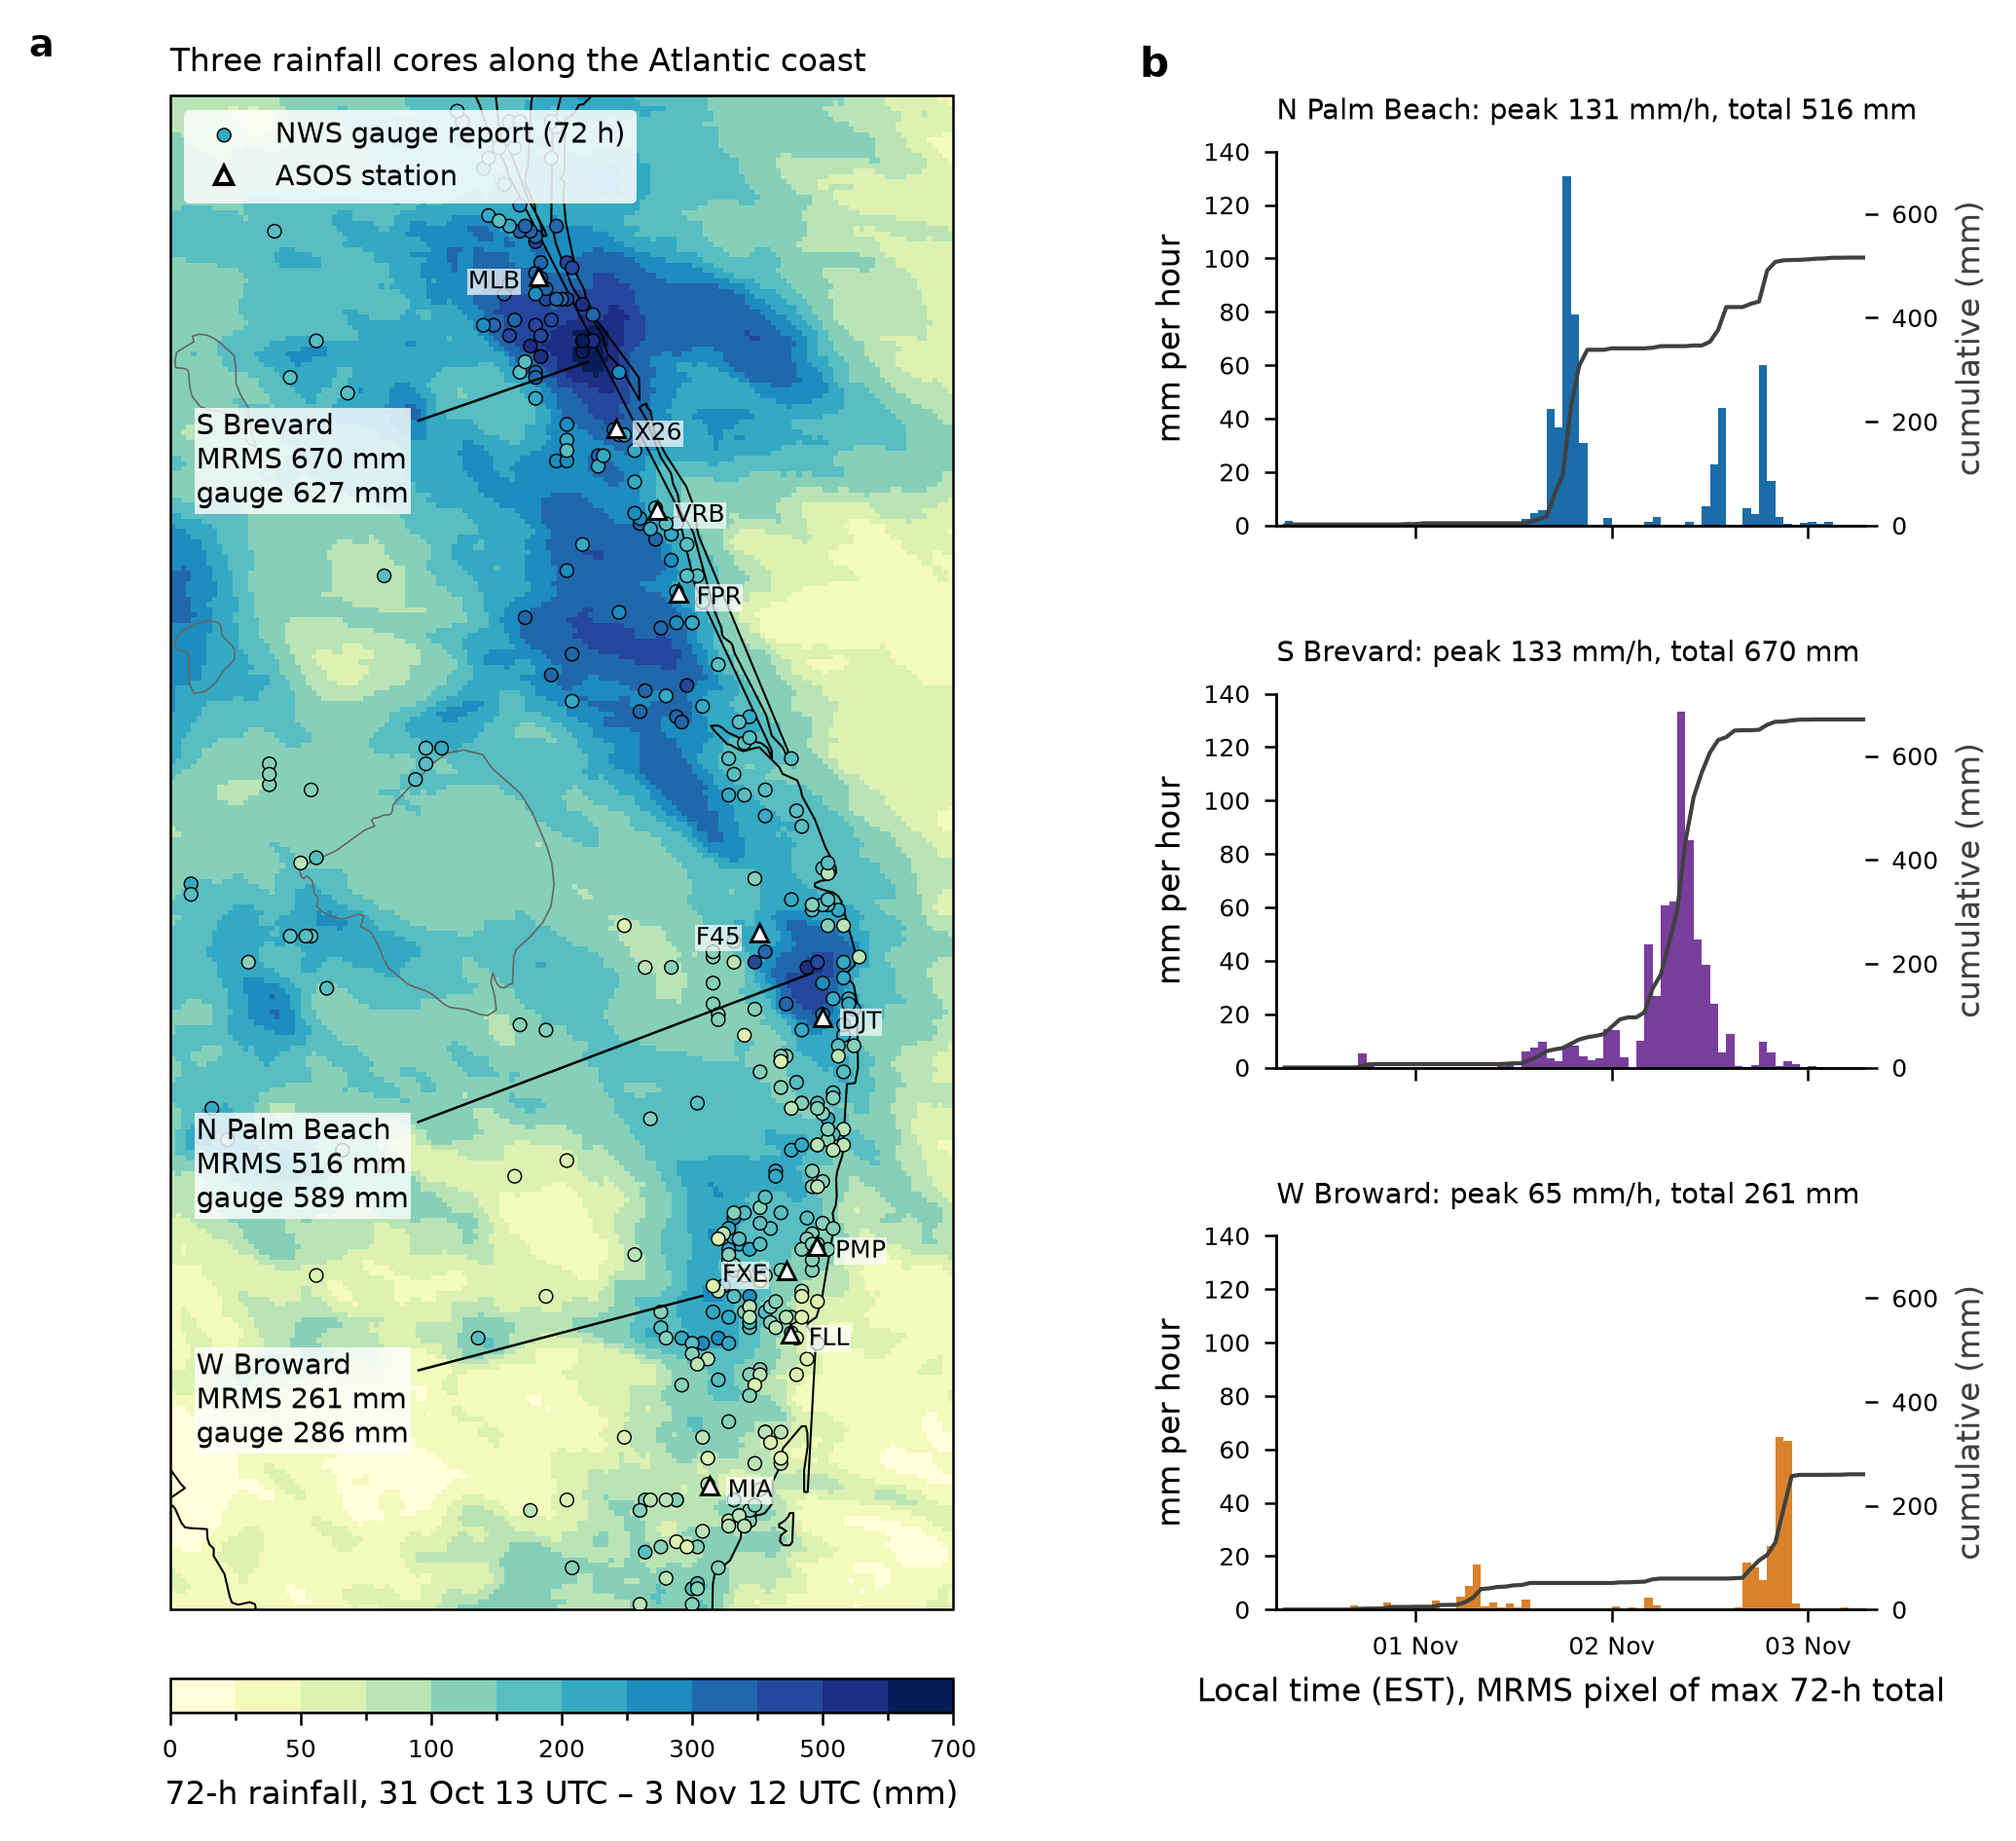

In [ ]:
# [orig cell 38 | env: precip | status: ok]
ax.get_legend().remove(); ax.legend(loc='upper left',frameon=True,fontsize=7,framealpha=.85,edgecolor='none')
fig.canvas.draw(); pb=ax.get_position(); cax.set_position([pb.x0,0.075,pb.width,0.018])
fig.savefig('fig1_rainfall_cores.png',dpi=300)
r=fig.canvas.get_renderer()
texts=[(t,t.get_window_extent(r)) for t in fig.findobj(mpl.text.Text) if t.get_text().strip() and t.get_visible()]
print([(a.get_text()[:20],b.get_text()[:20]) for i,(a,ba) in enumerate(texts) for b,bb in texts[i+1:] if ba.overlaps(bb) and 'rainfall, 31' not in a.get_text() and 'Local' not in a.get_text()][:10])


In [ ]:
# [orig cell 39 | env: precip | status: ok]
plt.close('all')
t0=pd.Timestamp('2026-11-02 00:00'); d=D.sel(time=t0)
o=xr.open_dataset('event/oisst_20261101.nc').squeeze(); o=o.assign_coords(lon=(o.lon+180)%360-180).sortby('lon')
PWc=pd.read_csv('event/kmfl_pwat.csv',parse_dates=['validUTC']).set_index('validUTC')
clim=PWc[(PWc.year<=2025)&(PWc.index.month==11)]; evp=PWc['2026-11-01':'2026-11-03 12:00']
proj=ccrs.PlateCarree(); E=[-95,-62,17,40]
fig=plt.figure(figsize=(7.2,6.6))
def base(pos):
    a=fig.add_axes(pos,projection=proj); a.set_extent(E,crs=proj)
    a.add_feature(cf.COASTLINE.with_scale('50m'),lw=.4); a.add_feature(cf.STATES.with_scale('50m'),lw=.2,ec='0.5'); return a
# a IVT
a=base([0.04,0.53,0.44,0.40])
ivl=[0,100,250,400,550,700,850]
c=a.contourf(D.lon,D.lat,d.ivt,levels=ivl,cmap='YlOrBr',extend='max')
a.contour(D.lon,D.lat,d.ivt,levels=[250],colors='k',linewidths=.6)
sk=8; a.quiver(D.lon[::sk],D.lat[::sk],d.ivtu[::sk,::sk],d.ivtv[::sk,::sk],scale=12000,width=.0025,color='0.15')
cs=a.contour(D.lon,D.lat,d.mslp,levels=np.arange(1000,1040,4),colors='#1b4f8a',linewidths=.6); a.clabel(cs,fontsize=5,fmt='%d')
a.plot(-80.11,26.78,marker='*',ms=8,mfc='#c0392b',mec='w',mew=.5)
cb=fig.colorbar(c,ax=a,orientation='horizontal',fraction=.05,pad=.03); cb.set_label('IVT (kg m$^{-1}$ s$^{-1}$); black = 250; blue = MSLP (hPa)')
a.set_title('Easterly moisture flux under a strong high, not a filament',loc='left',fontsize=7); panel_letter(a,'a')
# b PWAT + 500 hPa
b=base([0.54,0.53,0.44,0.40])
c2=b.contourf(D.lon,D.lat,d.pwat,levels=np.arange(10,61,5),cmap='GnBu',extend='max')
cs=b.contour(D.lon,D.lat,d.z500,levels=np.arange(552,600,3),colors='k',linewidths=.6); b.clabel(cs,fontsize=5,fmt='%d')
b.barbs(D.lon[::10],D.lat[::10],d.u850[::10,::10]*1.944,d.v850[::10,::10]*1.944,length=3.5,linewidth=.4,color='#7a3e9d')
b.plot(-80.11,26.78,marker='*',ms=8,mfc='#c0392b',mec='w',mew=.5)
cb=fig.colorbar(c2,ax=b,orientation='horizontal',fraction=.05,pad=.03); cb.set_label('PWAT (mm); contours 500 hPa height (dam); barbs 850 hPa (kt)')
b.set_title('Deep moisture under a weak Gulf upper trough',loc='left',fontsize=7); panel_letter(b,'b')
# c SST anomaly
cc=base([0.04,0.06,0.44,0.40])
c3=cc.pcolormesh(o.lon,o.lat,o.anom,cmap='RdBu_r',vmin=-3,vmax=3,shading='auto',rasterized=True)
cc.plot(-80.11,26.78,marker='*',ms=8,mfc='#c0392b',mec='w',mew=.5)
cb=fig.colorbar(c3,ax=cc,orientation='horizontal',fraction=.05,pad=.03,ticks=[-3,-2,-1,0,1,2,3]); cb.set_label('OISST anomaly, 1 Nov 2026 (°C, vs 1991–2020)')
cc.set_title('Gulf Stream and western Atlantic 1–2.6 °C warmer than normal',loc='left',fontsize=7); panel_letter(cc,'c')
# d KMFL PWAT
dd=fig.add_axes([0.60,0.12,0.36,0.32])
dd.hist(clim.pw_mm,bins=np.arange(10,70,2.5),color='0.75',edgecolor='w')
for t_,v in evp.pw_mm.items():
    pc=(clim.pw_mm<v).mean()*100
    dd.axvline(v,color='#1b6ca8',lw=1)
q99=clim.pw_mm.quantile(.99); dd.axvline(q99,color='k',ls='--',lw=.8); dd.text(q99+0.5,dd.get_ylim()[1]*.9,'99th',fontsize=6)
dd.text(evp.pw_mm.min()-0.8,dd.get_ylim()[1]*.75,'event\nsoundings',color='#1b6ca8',fontsize=6,ha='right')
dd.set_xlabel('Miami (KMFL) sounding PWAT (mm)'); dd.set_ylabel('soundings, 1–15 Nov 1991–2025')
dd.set_title(f'Moisture high (86–98th pct) but not record',loc='left',fontsize=7); panel_letter(dd,'d')
fig.text(0.04,0.965,'GFS 0.25° analysis, 00 UTC 2 Nov 2026 (7 pm EST 1 Nov, Palm Beach peak hour); red star = N Palm Beach core',fontsize=7)
fig.savefig('fig2_environment.png',dpi=300)
r=fig.canvas.get_renderer()
texts=[(t,t.get_window_extent(r)) for t in fig.findobj(mpl.text.Text) if t.get_text().strip() and t.get_visible()]
print([(a_.get_text()[:25],b_.get_text()[:25]) for i,(a_,ba) in enumerate(texts) for b_,bb in texts[i+1:] if ba.overlaps(bb)][:12])
print(evp.pw_mm.round(1).to_dict())


[('1024', 'GFS 0.25° analysis, 00 UT'), ('1024', 'IVT (kg m$^{-1}$ s$^{-1}$'), ('Easterly moisture flux un', '570'), ('IVT (kg m$^{-1}$ s$^{-1}$', '591'), ('552', '555'), ('567', 'GFS 0.25° analysis, 00 UT'), ('576', 'GFS 0.25° analysis, 00 UT'), ('576', 'Deep moisture under a wea'), ('OISST anomaly, 1 Nov 2026', '−3'), ('OISST anomaly, 1 Nov 2026', '−2'), ('OISST anomaly, 1 Nov 2026', '−1'), ('OISST anomaly, 1 Nov 2026', '0')]
{Timestamp('2026-11-01 00:00:00'): 45.6, Timestamp('2026-11-01 12:00:00'): 53.6, Timestamp('2026-11-02 00:00:00'): 53.0, Timestamp('2026-11-02 12:00:00'): 46.1, Timestamp('2026-11-03 00:00:00'): 55.9, Timestamp('2026-11-03 12:00:00'): 50.9}


ok


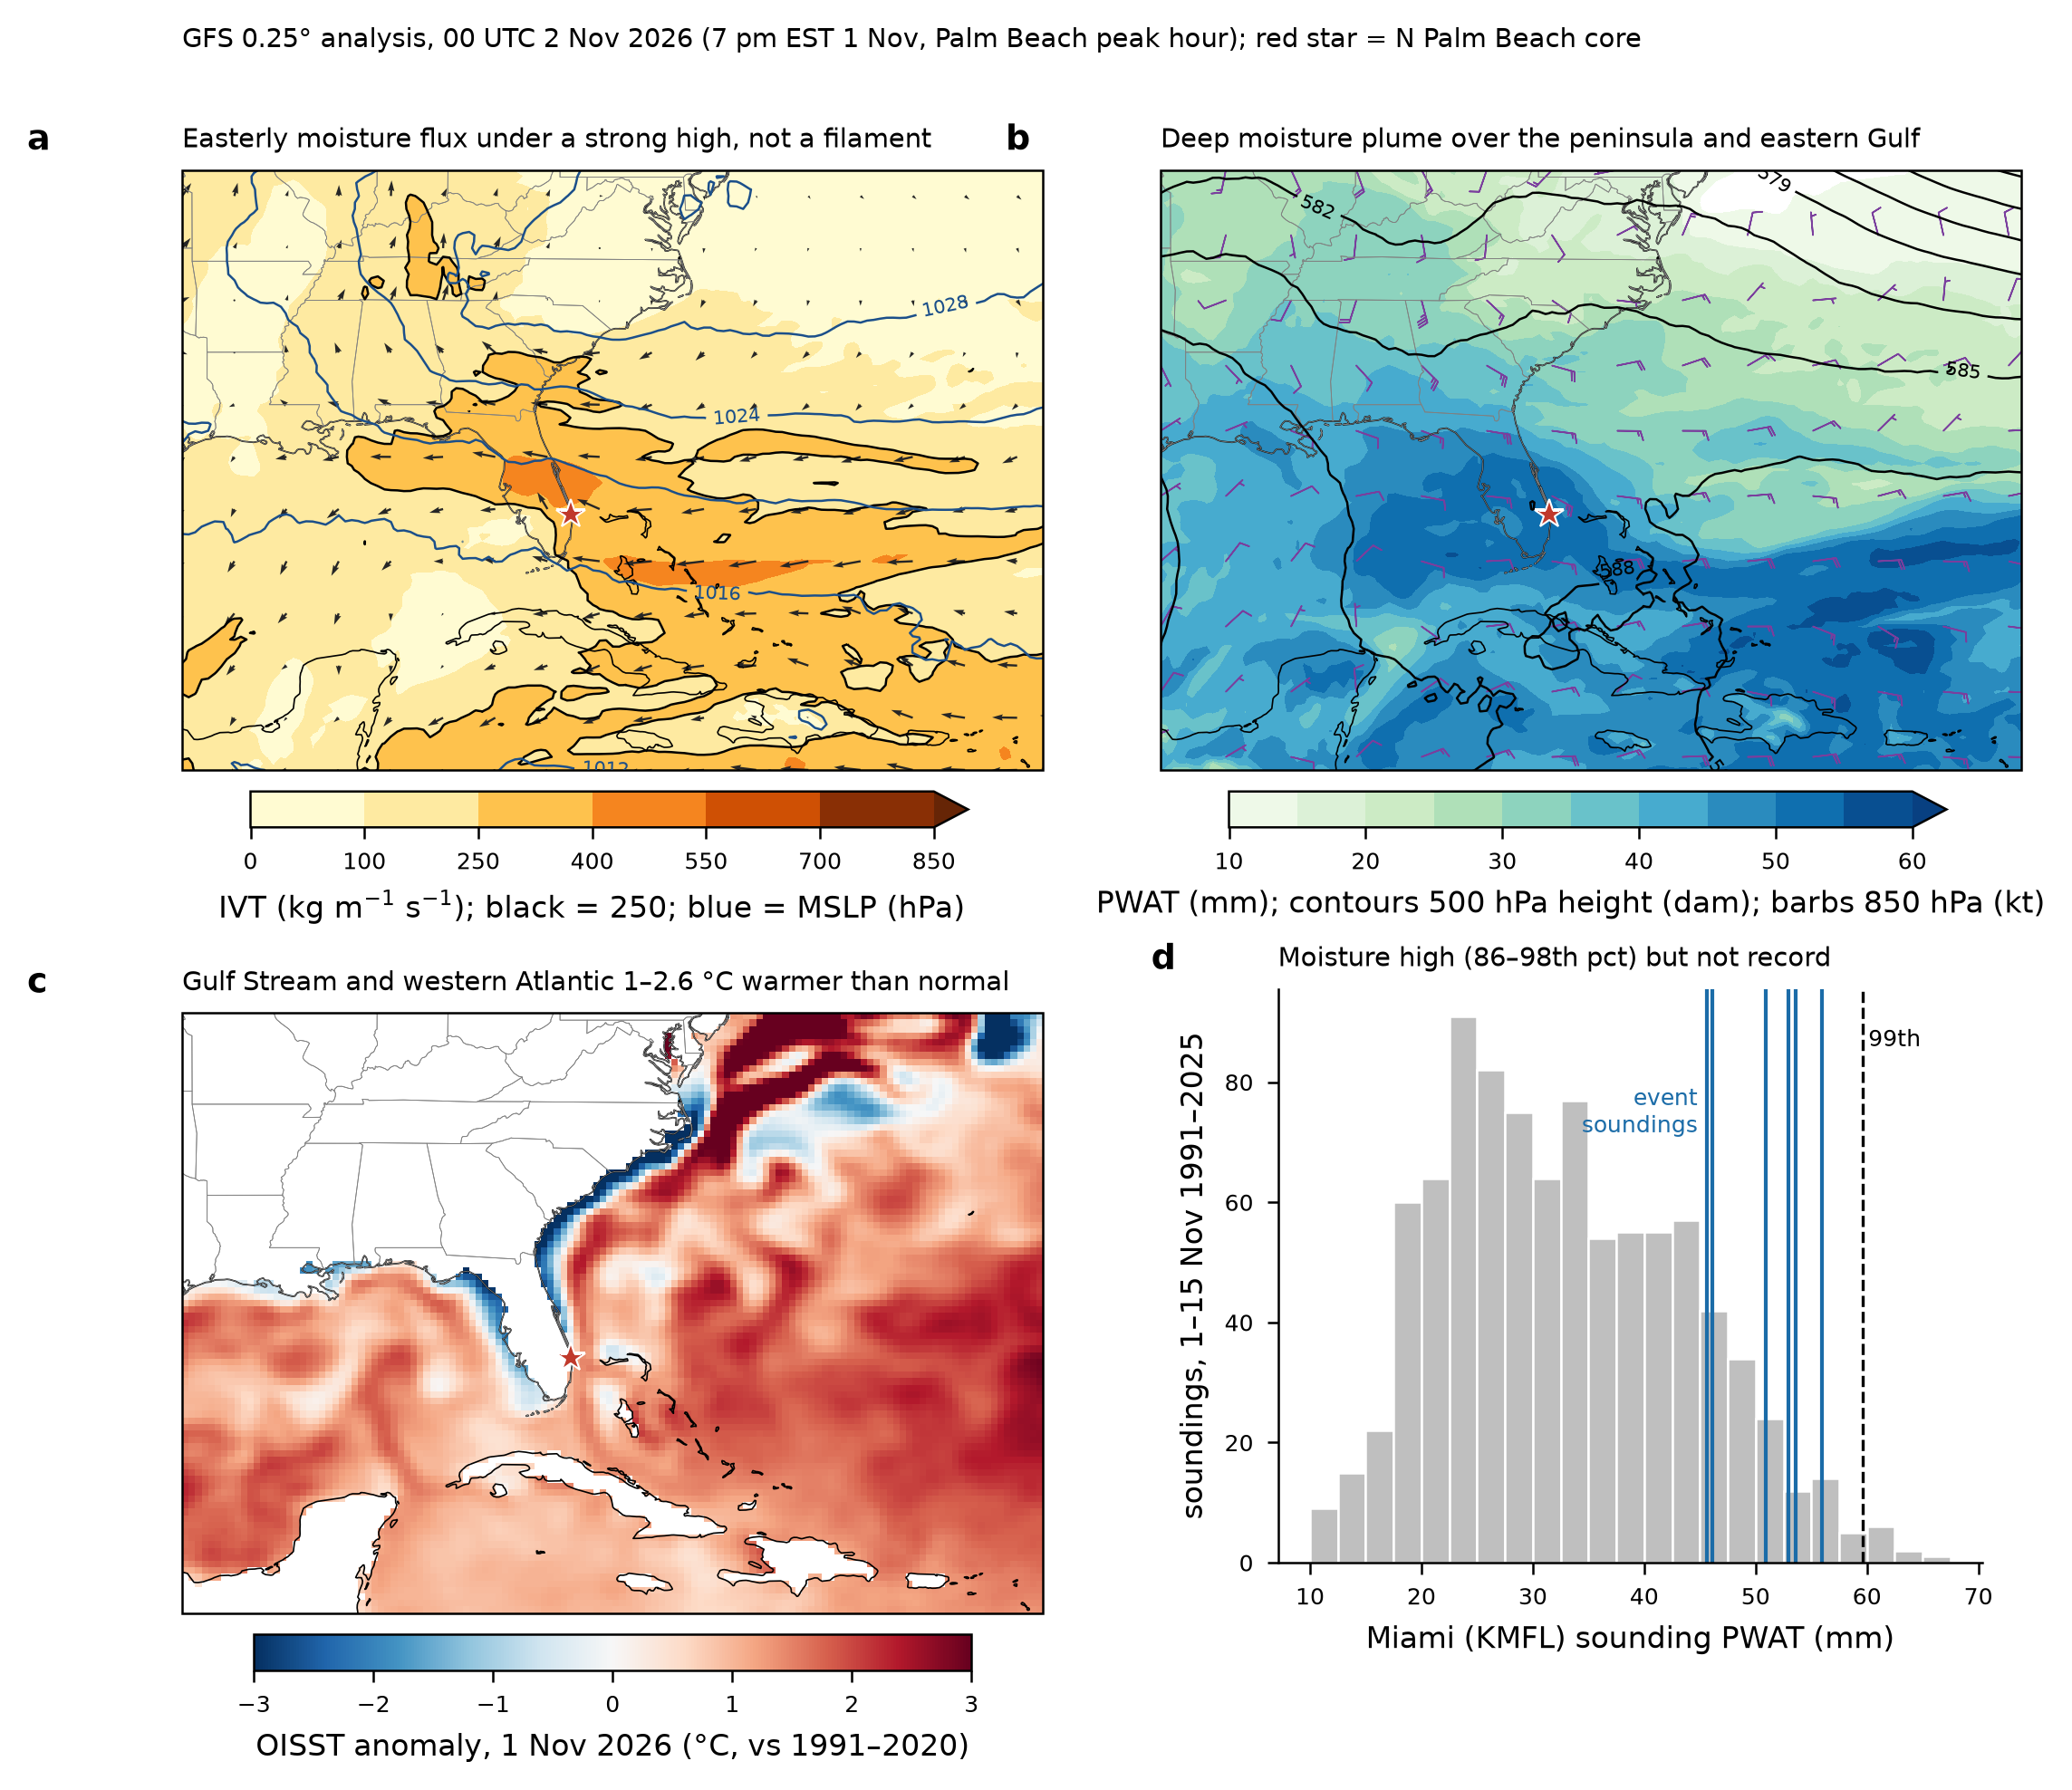

In [ ]:
# [orig cell 40 | env: precip | status: ok]
b.set_title('Deep moisture plume over the peninsula and eastern Gulf',loc='left',fontsize=7)
fig.savefig('fig2_environment.png',dpi=300)
AR.to_csv('event/ar_object_diagnostics.csv',index=False); Pt.to_csv('event/gfs_core_point_series.csv'); M.to_csv('event/mrms_core_maxima.csv',index=False)
import shutil
for f in ['asos_event_summary.csv','pns_72h_vs_mrms.csv','ar_object_diagnostics.csv','gfs_core_point_series.csv','mrms_core_maxima.csv','kmfl_pwat.csv','kmfl_kinematics.csv','lsr_MFL_MLB.csv']:
    shutil.copy(f'event/{f}',f)
print('ok')
